# Demo S-T-D model - spatial modelling vs 0D

This demo notebook shows how to plot and run, analyse and plot 2D and 0D spatial models of tissues.

- Showing effect of density sensing mechanism is low for parameters we ended up with (effectively 0D)
- Plotting tissue snapshots of clonal dynamics in M vs F mice
- Making clonal dynamics movies



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import voronoi_plot_2d
from numba import jit
import sys
sys.path.append("../analysis/")
sys.path.append("../sim/")
from tissue import *
import matplotlib.path as mplPath
import sim_model
import clones
import scipy.stats as stats
import os

%matplotlib inline


def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)
        

4 populations in sim
Starting sim with 400 cells at Fri Aug 21 11:47:34 2026
Ending sim with 400 cells at Fri Aug 21 11:51:09 2026
Starting sim with 400 cells at Fri Aug 21 11:51:09 2026
Ending sim with 432 cells at Fri Aug 21 11:54:59 2026
Resetting time and division times
Starting sim with 432 cells at Fri Aug 21 11:54:59 2026
Ending sim with 420 cells at Fri Aug 21 11:59:01 2026


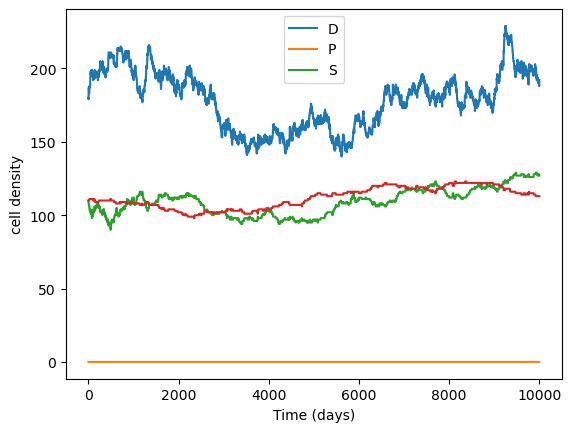

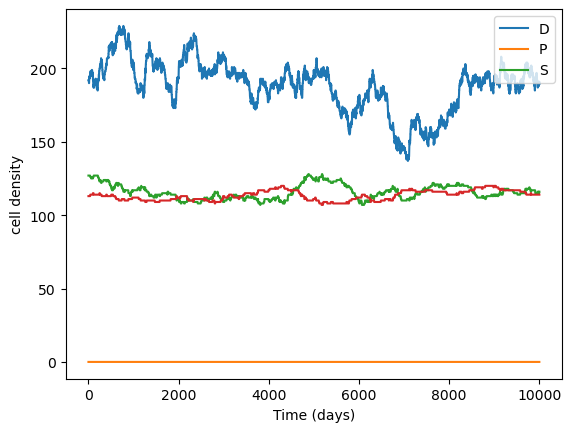

Starting sim with 5000 cells at Fri Aug 21 11:59:02 2026
Ending sim with 5357 cells at Fri Aug 21 11:59:18 2026
Resetting time and division times
Starting sim with 5357 cells at Fri Aug 21 11:59:23 2026
Ending sim with 5286 cells at Fri Aug 21 11:59:49 2026


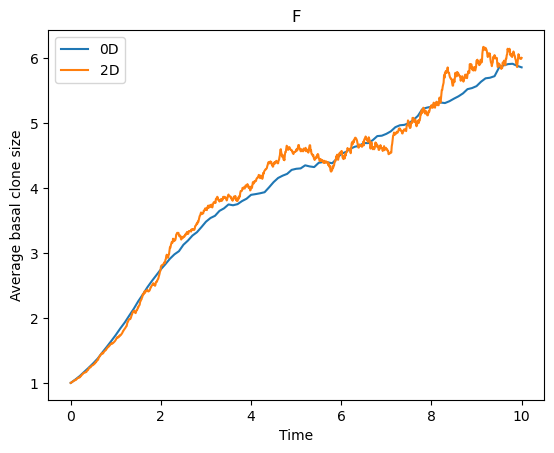

In [2]:
# Female mouse

sex = 'F'


#hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.9_corrSS_0.2_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_1.0_r_0.15_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl


tsteps = 10000#25000
skip = 10

tau  = 1000
shed = tau
sbas_cv = 0.1

L = 20
ncells = L**2

r = 0.15
rhoS = 0.275
q = 1.0
hilln = 8
cv_S = 0.5
cv_D = 1.0

corrST = 1.0
corrDD = 0.9
corrSS = 0.2
corrTT = corrSS
corrTD = 0.0

if os.path.exists(f'Figures/spatial_sim_{sex}.pkl'):
    results = load_object(f'Figures/spatial_sim_{sex}.pkl')
    t0 = results['tiss']
else:
    t0 = sim_model.ST2D_size(ncells, L, tau, rhoS = rhoS, r = r, q = q, hilln = hilln,
                    corrST = corrST, corrDD = corrDD, corrSS = corrSS, 
                    corrTT = corrTT, corrTD = corrTD, shed = shed, 
                    sbas_cv = sbas_cv, CVd_S = cv_S, CVd_T = cv_S, CVd_D = cv_D)


    results = t0.sim(tsteps = tsteps, skip = skip)

    resultsC = t0.simFull(tsteps = tsteps, skip = skip)
    t0.reset()
    results = t0.simFull(tsteps = tsteps, skip = skip, verbose = False)

    time = np.arange(0, tsteps+1, skip)/tau
    time0 = np.arange(0, tsteps+1)/tau



    plt.figure()
    plt.plot(np.arange(len(resultsC['ncells'])), resultsC['ncells'])
    plt.legend(['D', 'P', 'S',])
    plt.ylabel('cell density')
    plt.xlabel('Time (days)')
    plt.show()


    plt.figure()
    plt.plot(np.arange(len(results['ncells'])), results['ncells'])
    plt.legend(['D', 'P', 'S',])
    plt.ylabel('cell density')
    plt.xlabel('Time (days)')
    plt.show()


    results['tiss'] = t0
    save_object(results, f'Figures/spatial_sim_{sex}.pkl')


#assert(0)

tsteps = 1000#25000
skip = 10
tau  = 100
shed = tau
ncells = 5000

t0 = sim_model.ST2D_0D(ncells, tau, rhoS = rhoS, r = r, q = q, 
                corrST = corrST, corrDD = corrDD, corrSS = corrSS, 
                corrTT = corrTT, corrTD = corrTD, shed = shed, 
                sbas_cv = sbas_cv, CVd_S = cv_S, CVd_T = cv_S, CVd_D = cv_D)


resultsC = t0.simFull(tsteps = tsteps, skip = skip)
t0.reset()
results = t0.simFull(tsteps = tsteps, skip = skip, verbose = False)

time = np.arange(0, tsteps+1, skip)/tau
time0 = np.arange(0, tsteps+1)/tau



ca = clones.sanalysis(results, popnames = ['D', 'P', 'S'], skip = skip, 
                      containsBasal=True)


plt.figure()
plt.plot(ca.tvals/100, ca.av_bas_cs, label = '0D')
k = f'Figures/spatial_sim_{sex}.pkl'
results = load_object(k)
t0 = results['tiss']
ca2d = clones.sanalysis(results, popnames = ['D', 'P', 'S'], skip = skip, 
                      containsBasal=True)
plt.plot(ca2d.tvals/1000, ca2d.av_bas_cs, label = '2D')
plt.legend()    
plt.ylabel('Average basal clone size')
plt.xlabel('Time')
plt.title(sex)
plt.show()  



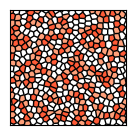

In [3]:
sex = 'F'
results = load_object(f'Figures/spatial_sim_{sex}.pkl')
t0 = results['tiss']

col = ['w', '#ffa07a80', '#ffa07a80', '#FF5B37']
plt.figure(figsize = (1.5,1.5))
voronoi_plot_2d(t0, show_vertices = False, show_points = False, ax=plt.gca())
for p in range(4):
    for c in range(t0.splits[p],t0.splits[p+1]):
        region = t0.regions[t0.point_region[c]]
        polygon = [t0.vertices[i] for i in region]
        plt.fill(*zip(*polygon), col[p], alpha = 1.0)
plt.axis('square')
plt.xlim([0,20])
plt.ylim([0,20])
plt.xticks([])
plt.yticks([])
plt.savefig('Figures/STD_tiled.pdf')
plt.show()

4 populations in sim
Starting sim with 400 cells at Sun Aug 23 13:40:35 2026
Ending sim with 400 cells at Sun Aug 23 13:44:04 2026
Starting sim with 400 cells at Sun Aug 23 13:44:04 2026
Ending sim with 417 cells at Sun Aug 23 13:48:16 2026
Resetting time and division times
Starting sim with 417 cells at Sun Aug 23 13:48:16 2026
Ending sim with 437 cells at Sun Aug 23 13:52:43 2026


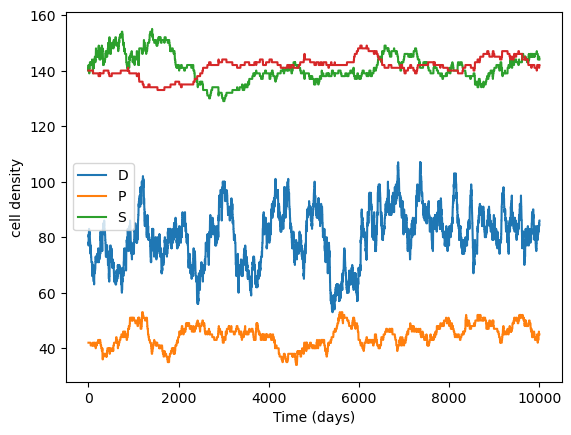

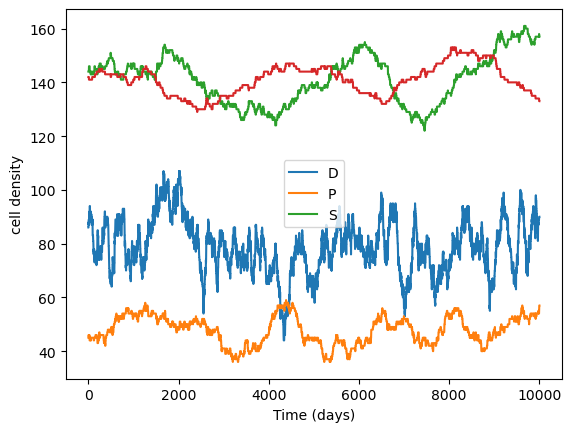

Starting sim with 5000 cells at Sun Aug 23 13:52:44 2026
Ending sim with 5323 cells at Sun Aug 23 13:53:16 2026
Resetting time and division times
Starting sim with 5323 cells at Sun Aug 23 13:53:24 2026
Ending sim with 5337 cells at Sun Aug 23 13:54:22 2026


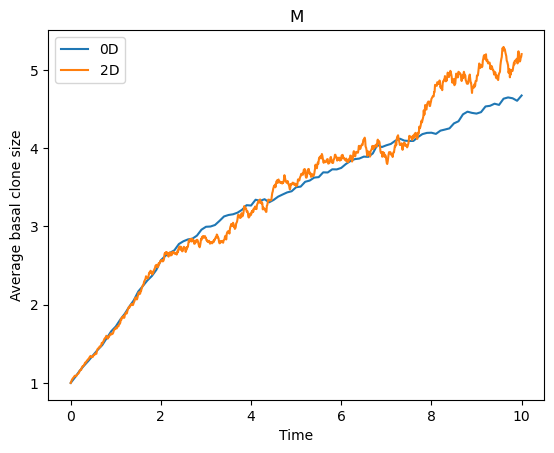

In [2]:
#hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_1.0_corrSS_0.8_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.5_r_0.15_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl



sex = 'M'

tsteps = 10000
skip = 10

tau  = 1000
shed = tau
sbas_cv = 0.2

L = 20
ncells = L**2

r = 0.15
rhoS = 0.35
q = 0.7
hilln = 32
cv_S = 0.5
cv_D = 0.7

corrST = 1.0
corrDD = 0.8
corrSS = 0.5
corrTT = corrSS
corrTD = 0.9

if os.path.exists(f'Figures/spatial_sim_{sex}.pkl'):
    results = load_object(f'Figures/spatial_sim_{sex}.pkl')
    t0 = results['tiss']
else:
    t0 = sim_model.ST2D_size(ncells, L, tau, rhoS = rhoS, r = r, q = q, hilln = hilln,
                    corrST = corrST, corrDD = corrDD, corrSS = corrSS, 
                    corrTT = corrTT, corrTD = corrTD, shed = shed, 
                    sbas_cv = sbas_cv, CVd_S = cv_S, CVd_T = cv_S, CVd_D = cv_D)


    results = t0.sim(tsteps = tsteps, skip = skip)

    resultsC = t0.simFull(tsteps = tsteps, skip = skip)
    t0.reset()
    results = t0.simFull(tsteps = tsteps, skip = skip, verbose = False)

    time = np.arange(0, tsteps+1, skip)/tau
    time0 = np.arange(0, tsteps+1)/tau



    plt.figure()
    plt.plot(np.arange(len(resultsC['ncells'])), resultsC['ncells'])
    plt.legend(['D', 'P', 'S',])
    plt.ylabel('cell density')
    plt.xlabel('Time (days)')
    plt.show()


    plt.figure()
    plt.plot(np.arange(len(results['ncells'])), results['ncells'])
    plt.legend(['D', 'P', 'S',])
    plt.ylabel('cell density')
    plt.xlabel('Time (days)')
    plt.show()


    results['tiss'] = t0
    save_object(results, f'Figures/spatial_sim_{sex}.pkl')


tsteps = 1000#25000
skip = 10
tau  = 100
shed = tau
ncells = 5000

t0 = sim_model.ST2D_0D(ncells, tau, rhoS = rhoS, r = r, q = q, 
                corrST = corrST, corrDD = corrDD, corrSS = corrSS, 
                corrTT = corrTT, corrTD = corrTD, shed = shed, 
                sbas_cv = sbas_cv, CVd_S = cv_S, CVd_T = cv_S, CVd_D = cv_D)


resultsC = t0.simFull(tsteps = tsteps, skip = skip)
t0.reset()
results = t0.simFull(tsteps = tsteps, skip = skip, verbose = False)

time = np.arange(0, tsteps+1, skip)/tau
time0 = np.arange(0, tsteps+1)/tau



ca = clones.sanalysis(results, popnames = ['D', 'P', 'S'], skip = skip, 
                      containsBasal=True)


plt.figure()
plt.plot(ca.tvals/100, ca.av_bas_cs, label = '0D')
k = f'Figures/spatial_sim_{sex}.pkl'
results = load_object(k)
t0 = results['tiss']
ca2d = clones.sanalysis(results, popnames = ['D', 'P', 'S'], skip = skip, 
                      containsBasal=True)
plt.plot(ca2d.tvals/1000, ca2d.av_bas_cs, label = '2D')
plt.legend()    
plt.ylabel('Average basal clone size')
plt.xlabel('Time')
plt.title(sex)
plt.show()  



Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c
Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c
Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c
Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c
Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c
Clone 10004 r
Clone 9744 g
Clone 10085 y
Clone 10015 b
Clone 9326 m
Clone 9141 c


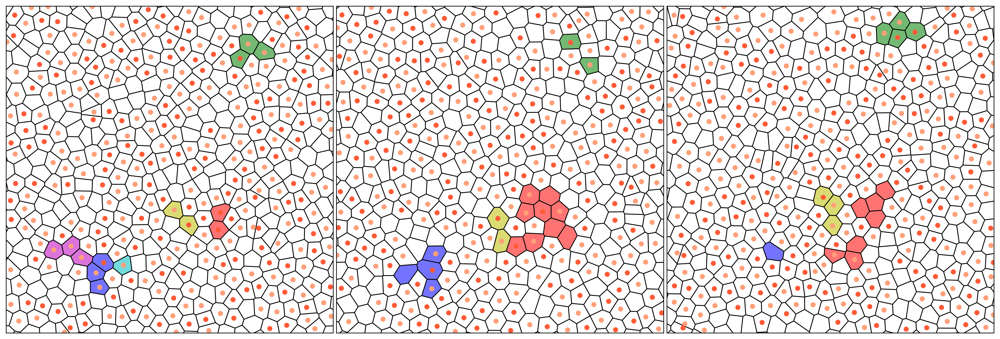

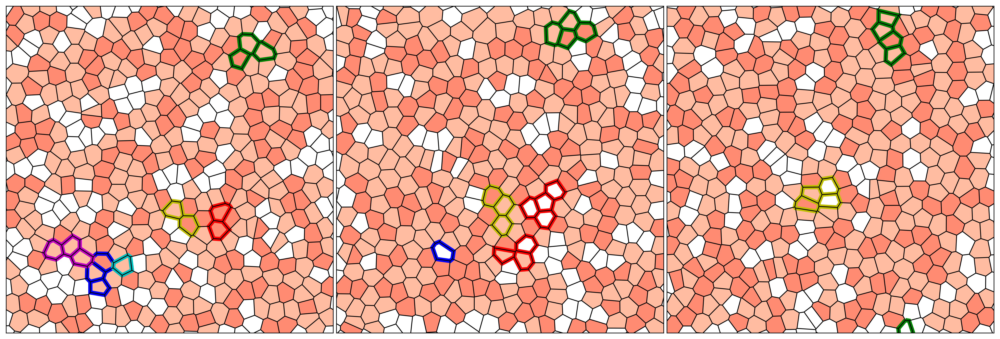

In [ ]:
''' 
    Note: the clone selection to stochastic, to select fixed clones set a list for track
'''


sys.path.append("../plot/")

import tissplot as tplt
from importlib import reload
reload(tplt)



# Sample random clones
track = 8 
sample_mode = -10 # -10: sample from all clones, -20: sample from surviving clones, -30: sample from extinct clones

track = [10004, 9744, 10085, 10015, 9326, 9141] #fixed clones, comment out for random

sex = 'M'
k = f'Figures/spatial_sim_{sex}.pkl'
results = load_object(k)
t0 = results['tiss']
#7
tplt.clonal_snapshot(t0, results, times = [int(1000*14/7),int(1000*28/7),int(1000*42/7)], 
                     track = track, sample_mode = sample_mode, cloneResults = None, 
                    skip = results['skip'], titles = ['','',''], markpops = True, use_legend = False,
                    popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                    fillpops = False, fillclones = True)
plt.savefig(f'Figures/F3_snapshot_fill_{sex}.pdf', dpi = 300, bbox_inches = 'tight')

tplt.clonal_snapshot(t0, results, times = [int(1000*14/7),int(1000*42/7),int(1000*56/7)], 
                     track = track, sample_mode = sample_mode, cloneResults = None, 
                    skip = results['skip'], titles = ['','',''], markpops = False, use_legend = False,
                    popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                    fillpops = True, fillclones = False)
plt.savefig(f'Figures/F3_snapshot_outline_{sex}.pdf', dpi = 300, bbox_inches = 'tight')





6
Moviepy - Building video sim_ctr_M.mp4.
Moviepy - Writing video sim_ctr_M.mp4



Moviepy - Done !
Moviepy - video ready sim_ctr_M.mp4


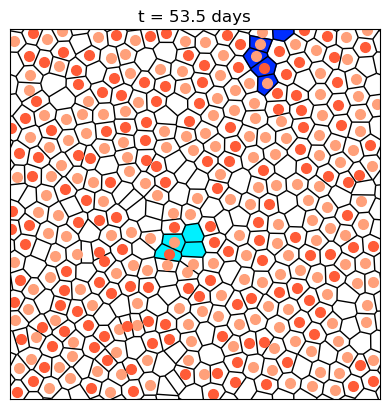

In [3]:
import tissplot as tplt
from importlib import reload
reload(tplt)

tiss = t0
positions = results['cellpos']
ancs = results['anc']
ancs = {**ancs[0], **ancs[1], **ancs[2], **ancs[3]}

cellid = results['cellid']
ncells = results['ncells']

col = ['w', '#ffa07a80', '#ffa07a80', '#FF5B37']

animation = tplt.clone_movies(positions, ancs, cellid, ncells = ncells, track = track, 
                         nsteps = 400, savename = f'sim_ctr_{sex}.mp4', fps = 10, 
                         saveskip = 10, diebytime = None, 
                         delambytime = None, L = 20,
                         tscale = 1000/6.7, tshift = 0, skip = 2,
                         popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                        fillpops = False, fillclones = True, use_legend = False); 

Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c
Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c
Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c
Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c
Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c
Clone 6658 r
Clone 6299 g
Clone 6633 y
Clone 6331 b
Clone 6370 m
Clone 6282 c


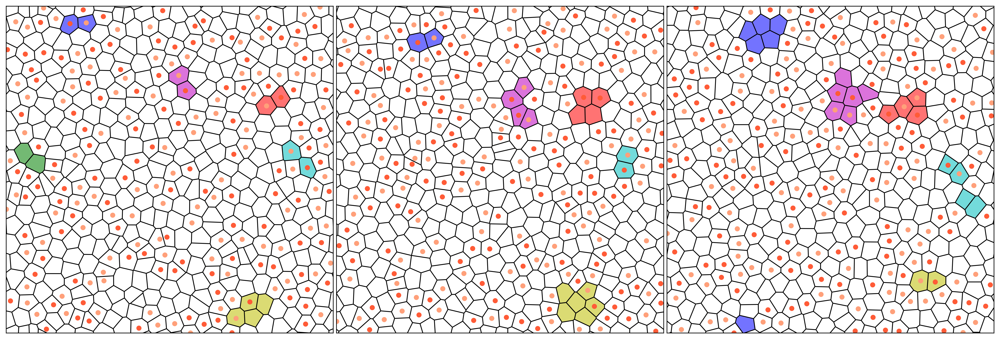

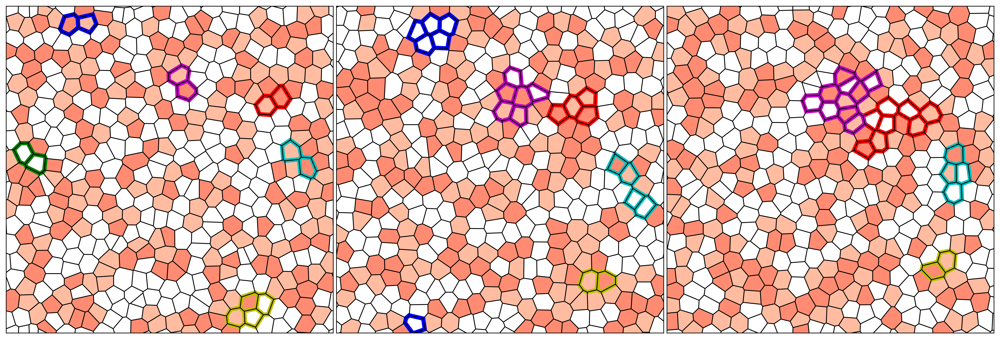

In [7]:
''' 
    Plot for females

    Note: the clone selection to stochastic, to select fixed clones set a list for track
'''

# Sample random clones
track = 8 
sample_mode = -10 # -10: sample from all clones, -20: sample from surviving clones, -30: sample from extinct clones

track = [6658, 6299, 6633, 6331, 6370, 6282] #fixed clones, comment out for random

sex = 'F'
k = f'Figures/spatial_sim_{sex}.pkl'
results = load_object(k)
t0 = results['tiss']
#7
tplt.clonal_snapshot(t0, results, times = [int(1000*14/7),int(1000*28/7),int(1000*42/7)], 
                     track = track, sample_mode = sample_mode, cloneResults = None, 
                    skip = results['skip'], titles = ['','',''], markpops = True, use_legend = False,
                    popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                    fillpops = False, fillclones = True)
plt.savefig(f'Figures/F3_snapshot_fill_{sex}.pdf', dpi = 300, bbox_inches = 'tight')

tplt.clonal_snapshot(t0, results, times = [int(1000*14/7),int(1000*42/7),int(1000*56/7)], 
                     track = track, sample_mode = sample_mode, cloneResults = None, 
                    skip = results['skip'], titles = ['','',''], markpops = False, use_legend = False,
                    popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                    fillpops = True, fillclones = False)
plt.savefig(f'Figures/F3_snapshot_outline_{sex}.pdf', dpi = 300, bbox_inches = 'tight')


6
Moviepy - Building video sim_ctr_F.mp4.
Moviepy - Writing video sim_ctr_F.mp4



Moviepy - Done !
Moviepy - video ready sim_ctr_F.mp4


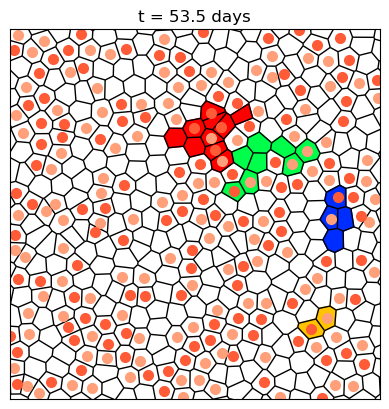

In [8]:
import tissplot as tplt
from importlib import reload
reload(tplt)

tiss = t0
positions = results['cellpos']
ancs = results['anc']
ancs = {**ancs[0], **ancs[1], **ancs[2], **ancs[3]}

cellid = results['cellid']
ncells = results['ncells']

col = ['w', '#ffa07a80', '#ffa07a80', '#FF5B37']

animation = tplt.clone_movies(positions, ancs, cellid, ncells = ncells, track = track, 
                         nsteps = 400, savename = f'sim_ctr_{sex}.mp4', fps = 10, 
                         saveskip = 10, diebytime = None, 
                         delambytime = None, L = 20,
                         tscale = 1000/6.7, tshift = 0, skip = 2,
                         popcols = ['w', 'lightsalmon', 'lightsalmon', '#FF5B37'],
                        fillpops = False, fillclones = True, use_legend = False); 